# Qui utilise mon appli ? Identification des utilisateurs de Copilote

**Le problème.** Chaque ligne des données est une *session* du logiciel Copilote : le navigateur utilisé puis la liste des actions faites. On doit deviner **quel utilisateur** (parmi 247) a fait la session. C'est une **classification supervisée** à 247 classes.

**Plan du notebook.**
1. Charger les données
2. Comprendre le format d'une action
3. Explorer les données
4. Transformer chaque session en texte
5. Comparer plusieurs modèles
6. Voir ce qui améliore le score
7. Comprendre les erreurs et le modèle
8. Créer le fichier de soumission

In [1]:
import csv
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

GRIS, BLEU = "#b4b2a9", "#2a78d6"  # gris pour les données, bleu pour ce qu'on veut montrer
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "axes.axisbelow": True, "axes.titleweight": "bold"})
pourcent = PercentFormatter(1.0)  # affiche 0.95 comme 95 %

## 1. Charger les données

Format d'une ligne du train : `utilisateur, navigateur, action, action, ...` (le test n'a pas la colonne utilisateur).

**Pourquoi ne pas utiliser `pd.read_csv` ?** Les sessions n'ont pas la même longueur : la plus longue a plus de 14 000 actions. Pandas créerait alors 14 000 colonnes, presque toutes vides, et la « colonne 57 » ne voudrait rien dire (la 57e action de deux sessions n'a rien en commun). On lit donc chaque ligne comme une **liste**.

In [2]:
def lire(chemin, avec_utilisateur):
    utilisateurs, navigateurs, sessions = [], [], []
    with open(chemin, encoding="utf-8") as f:
        for ligne in csv.reader(f):
            if avec_utilisateur:
                utilisateurs.append(ligne.pop(0))
            navigateurs.append(ligne[0])
            sessions.append(ligne[1:])
    return np.array(utilisateurs), navigateurs, sessions

y, nav, sessions = lire("data/train.csv", avec_utilisateur=True)
_, nav_test, sessions_test = lire("data/test.csv", avec_utilisateur=False)

print(len(sessions), "sessions d'entraînement,", len(set(y)), "utilisateurs,", len(sessions_test), "sessions de test")
print("Exemple :", y[0], nav[0], sessions[0][:5])

3279 sessions d'entraînement, 247 utilisateurs, 324 sessions de test
Exemple : nuh Firefox ["Création d'un écran(infologic.core.accueil.AccueilController)", "Affichage d'une dialogue", "Exécution d'un bouton", "Fermeture d'une dialogue", "Affichage d'une dialogue"]


## 2. Comprendre le format d'une action

D'après la description des données, une action peut contenir plusieurs informations :

| Motif | Sens | Exemple |
|---|---|---|
| texte avant `(`, `<` ou `$` | le type d'action | `Saisie dans un champ` |
| `(...)` | l'écran | `(infologic.crm.modules.CRM_ANNUAIRE.AnnuaireController)` |
| `<...>` | la configuration d'écran | `<DEF_03/24>` |
| `$...$` | la chaîne (catégorie de fiche) | `$GP$` |
| `1` à la fin | la fiche est en modification | `Saisie dans un champ1` |

Les jetons `t5`, `t10`, `t15`... ne sont **pas des actions** : ce sont des repères de temps en secondes.

On écrit une fonction qui découpe une action avec des expressions régulières.

In [3]:
RE_TEMPS = re.compile(r"t\d+")

def decouper(action):
    modif = action.endswith("1")
    if modif:
        action = action[:-1]
    return {
        "type": re.split(r"[(<$]", action)[0].strip(),
        "ecrans": [e.split(".")[-1] for e in re.findall(r"\((.*?)\)", action)],  # on garde la fin du nom
        "configs": re.findall(r"<(.*?)>", action),
        "chaines": re.findall(r"\$(.*?)\$", action),
        "modif": modif,
    }

decouper("Saisie dans un champ(MAINT)<DEF_03/24>$GP$1")

{'type': 'Saisie dans un champ',
 'ecrans': ['MAINT'],
 'configs': ['DEF_03/24'],
 'chaines': ['GP'],
 'modif': True}

Avec cette fonction, on calcule quelques statistiques simples par session : nombre d'actions, durée (le plus grand repère `tXX`), nombre d'écrans différents.

In [4]:
def statistiques(session):
    temps = [int(j[1:]) for j in session if RE_TEMPS.fullmatch(j)]
    actions = [decouper(j) for j in session if not RE_TEMPS.fullmatch(j)]
    return {
        "nb_actions": len(actions),
        "duree_s": max(temps, default=0),
        "nb_types": len({a["type"] for a in actions}),
        "nb_ecrans": len({e for a in actions for e in a["ecrans"]}),
    }

stats = pd.DataFrame([statistiques(s) for s in sessions])
stats["utilisateur"] = y
stats["navigateur"] = nav
stats_test = pd.DataFrame([statistiques(s) for s in sessions_test])
stats.describe().round(1)

,nb_actions,duree_s,nb_types,nb_ecrans
count,3279.0,3279.0,3279.0,3279.0
mean,692.4,751.5,17.0,10.7
std,1005.9,1006.3,4.3,5.8
min,0.0,5.0,0.0,0.0
25%,153.0,185.0,14.0,6.0
50%,340.0,395.0,17.0,9.0
75%,818.5,945.0,20.0,14.0
max,11977.0,11790.0,29.0,42.0


## 3. Explorer les données

### 3.1 Combien de sessions par utilisateur ?

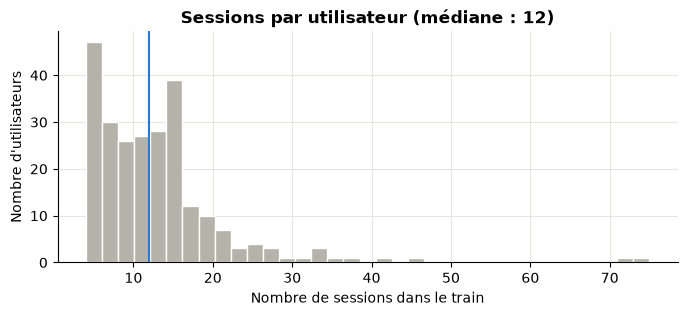

Minimum : 4 | maximum : 75
Si on répond toujours l'utilisateur le plus fréquent : 2.3% de bonnes réponses


In [5]:
sessions_par_util = stats.utilisateur.value_counts()

plt.figure(figsize=(8, 3))
plt.hist(sessions_par_util, bins=35, color=GRIS, edgecolor="white")
plt.axvline(sessions_par_util.median(), color=BLEU)
plt.title(f"Sessions par utilisateur (médiane : {sessions_par_util.median():.0f})")
plt.xlabel("Nombre de sessions dans le train")
plt.ylabel("Nombre d'utilisateurs")
plt.show()

print("Minimum :", sessions_par_util.min(), "| maximum :", sessions_par_util.max())
print(f"Si on répond toujours l'utilisateur le plus fréquent : {sessions_par_util.max() / len(y):.1%} de bonnes réponses")

**Ce qu'on retient.**
- 247 classes, mais **peu d'exemples par classe** : 12 sessions en médiane, 4 au minimum. Le modèle devra apprendre un utilisateur à partir de très peu de sessions.
- Les classes sont **déséquilibrées** (de 4 à 75 sessions), sans qu'un utilisateur domine : répondre toujours le plus fréquent ne donne que 2,3 %.
- Le hasard pur donnerait 1/247 = 0,4 %. Ce sont nos deux repères pour juger un modèle.

### 3.2 Le navigateur

In [6]:
print("Nombre de navigateurs différents par utilisateur :", stats.groupby("utilisateur").navigateur.nunique().value_counts().to_dict())
print("Nombre d'utilisateurs par navigateur :", stats.groupby("navigateur").utilisateur.nunique().to_dict())
print("Sessions de test par navigateur :", pd.Series(nav_test).value_counts().to_dict())

Nombre de navigateurs différents par utilisateur : {1: 247}
Nombre d'utilisateurs par navigateur : {'Firefox': 114, 'Google Chrome': 93, 'Microsoft Edge': 39, 'Opera': 1}
Sessions de test par navigateur : {'Firefox': 147, 'Google Chrome': 133, 'Microsoft Edge': 42, 'Opera': 2}


**Ce qu'on retient.**
- **Chaque utilisateur n'utilise qu'un seul navigateur.** C'est une information précieuse : une session Edge ne peut venir que d'un des 39 utilisateurs d'Edge, et pas des 247.
- Opera n'a qu'un seul utilisateur : les 2 sessions de test sous Opera viennent presque sûrement de lui.
- Le test a à peu près la même répartition de navigateurs que le train. Ce qu'on apprend sur le train devrait donc bien se transposer.

### 3.3 Longueur des sessions : y a-t-il des valeurs aberrantes ?

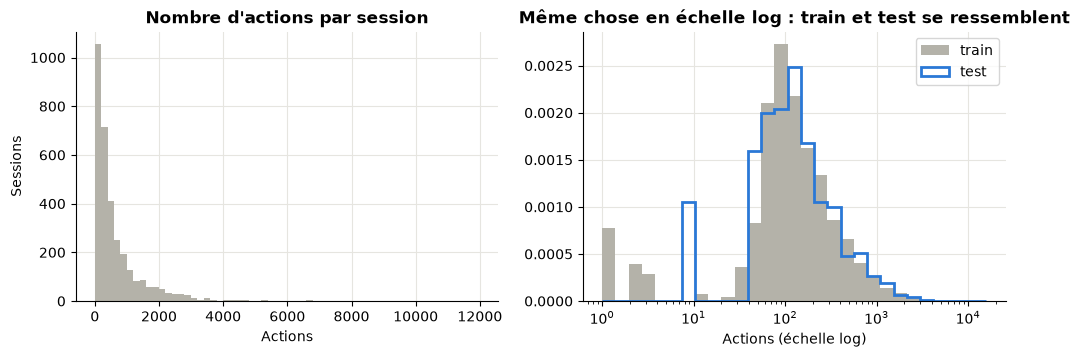

Sessions sans aucune action : 1
Seuil du 1 % de sessions les plus longues : 4697.199999999988 actions


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))

ax1.hist(stats.nb_actions, bins=60, color=GRIS)
ax1.set(title="Nombre d'actions par session", xlabel="Actions", ylabel="Sessions")

bins = np.logspace(0, 4.2, 30)
ax2.hist(stats.nb_actions + 1, bins=bins, color=GRIS, density=True, label="train")
ax2.hist(stats_test.nb_actions + 1, bins=bins, histtype="step", lw=2, color=BLEU, density=True, label="test")
ax2.set(xscale="log", title="Même chose en échelle log : train et test se ressemblent", xlabel="Actions (échelle log)")
ax2.legend()
plt.show()

print("Sessions sans aucune action :", (stats.nb_actions == 0).sum())
print("Seuil du 1 % de sessions les plus longues :", stats.nb_actions.quantile(0.99), "actions")

**Ce qu'on retient.**
- La distribution est très **asymétrique** : la plupart des sessions ont quelques centaines d'actions, mais certaines en ont plus de 10 000 (une journée de travail sans se déconnecter).
- **Faut-il supprimer ces valeurs extrêmes ?** Non :
    - ce ne sont pas des erreurs de saisie, mais des sessions réelles ;
    - le test contient le même genre de sessions (même distribution en échelle log) ;
    - certains utilisateurs n'ont que 4 sessions, on ne peut pas se permettre d'en perdre ;
    - la représentation choisie plus bas (TF-IDF avec logarithme et normalisation) empêche une session longue de peser plus qu'une autre.
- Une seule session n'a aucune action (que des repères de temps) : elle ne peut être reconnue que par son navigateur.

### 3.4 Les types d'action

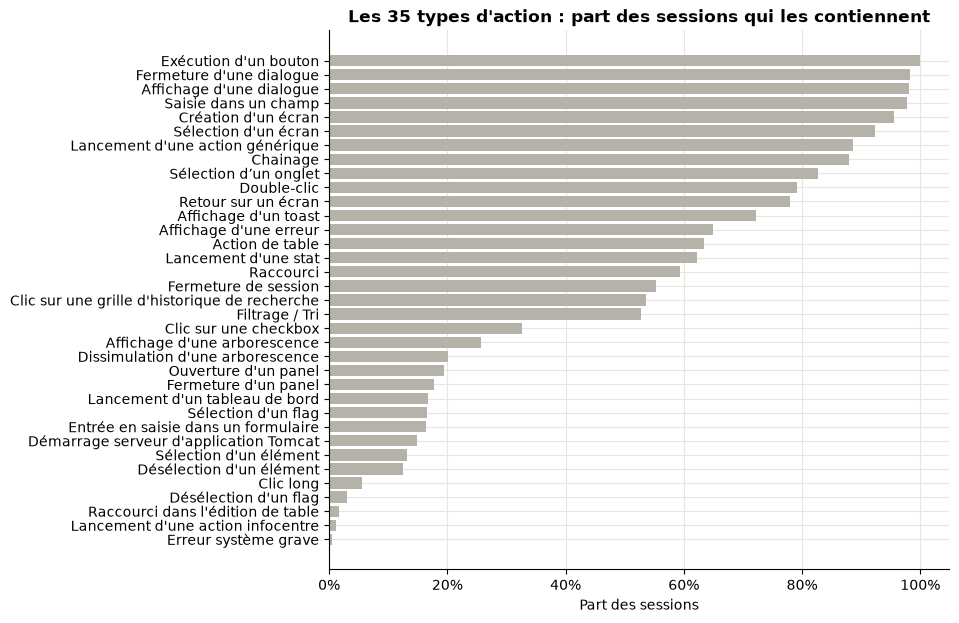

In [8]:
compte = Counter()
for s in sessions:
    compte.update({decouper(j)["type"] for j in s if not RE_TEMPS.fullmatch(j)})  # présence dans la session
presence = pd.Series(compte).sort_values() / len(sessions)

plt.figure(figsize=(8, 7))
plt.barh(presence.index, presence.values, color=GRIS)
plt.title(f"Les {len(presence)} types d'action : part des sessions qui les contiennent")
plt.xlabel("Part des sessions")
plt.gca().xaxis.set_major_formatter(pourcent)
plt.show()

**Ce qu'on retient.**
- Il n'y a que **35 types d'action**, et les plus courants (exécuter un bouton, ouvrir une dialogue, saisir un champ) sont dans presque toutes les sessions : ils ne permettent pas de distinguer les utilisateurs.
- Les actions rares (tableau de bord, flags, panels) sont plus intéressantes : elles sont propres à certains métiers.
- Il faudra donc **donner moins de poids aux actions que tout le monde fait** (c'est le rôle de l'IDF), et utiliser aussi les écrans, configurations et chaînes, beaucoup plus variés.

### 3.5 Les sessions d'un même utilisateur se ressemblent-elles ?

C'est la question clé : si deux sessions d'une même personne ne se ressemblent pas plus que deux sessions de personnes différentes, aucun modèle ne pourra marcher.

On représente chaque session par la fréquence de ses types d'action, et on mesure la ressemblance de deux sessions par la **similarité cosinus** (1 = même profil, 0 = rien en commun).

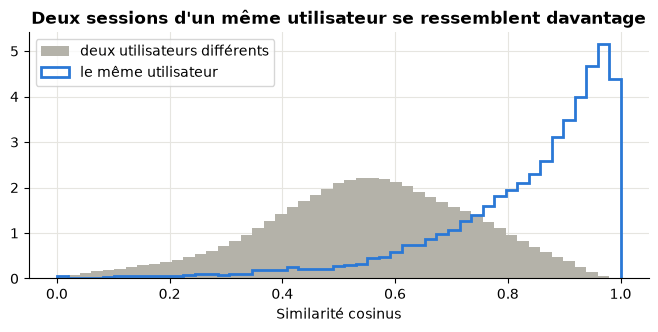

In [9]:
types_par_session = [" ".join(re.sub(r"\W+", "_", decouper(j)["type"]) for j in s if not RE_TEMPS.fullmatch(j)) for s in sessions]
X_types = TfidfVectorizer(token_pattern=r"\S+").fit_transform(types_par_session)
similarite = (X_types @ X_types.T).toarray()

meme_util = y[:, None] == y[None, :]
paires = np.triu(np.ones_like(similarite, dtype=bool), k=1)  # chaque paire une seule fois

plt.figure(figsize=(8, 3.2))
bins = np.linspace(0, 1, 50)
plt.hist(similarite[paires & ~meme_util], bins=bins, density=True, color=GRIS, label="deux utilisateurs différents")
plt.hist(similarite[paires & meme_util], bins=bins, density=True, histtype="step", lw=2, color=BLEU, label="le même utilisateur")
plt.title("Deux sessions d'un même utilisateur se ressemblent davantage")
plt.xlabel("Similarité cosinus")
plt.legend(loc="upper left")
plt.show()

**Ce qu'on retient.**
- Deux sessions d'un **même** utilisateur ont une similarité proche de 1 ; deux sessions de personnes **différentes** sont autour de 0,55. Chaque utilisateur a donc bien une « manière de travailler » reconnaissable : le problème est faisable.
- Mais les deux distributions se **chevauchent** : avec les seuls types d'action, certaines sessions de personnes différentes se ressemblent autant que celles d'une même personne. Il faudra d'autres informations (ordre des actions, écrans, chaînes).

## 4. Transformer chaque session en texte

Un modèle de machine learning a besoin d'un **vecteur de taille fixe** pour chaque session. L'idée : voir une session comme un **document** et ses actions comme des **mots**. On peut alors utiliser les outils de classification de textes.

Chaque action devient un ou plusieurs mots : son type, puis éventuellement son écran, sa configuration, sa chaîne et `MODIF`. Le navigateur devient un mot en début de session.

In [10]:
def mot(texte):
    """Transforme un texte en un seul mot (sans espaces ni ponctuation)."""
    return re.sub(r"\W+", "_", texte).strip("_")

def session_en_texte(session, navigateur, details=True, avec_nav=True):
    mots = ["NAV_" + mot(navigateur)] if avec_nav else []
    for jeton in session:
        if RE_TEMPS.fullmatch(jeton):
            continue
        a = decouper(jeton)
        mots.append(mot(a["type"]))
        if details:
            mots += ["ECRAN_" + mot(e) for e in a["ecrans"]]
            mots += ["CONF_" + mot(c) for c in a["configs"]]
            mots += ["CHAINE_" + mot(c) for c in a["chaines"]]
            if a["modif"]:
                mots.append("MODIF")
    return " ".join(mots)

textes = [session_en_texte(s, n) for s, n in zip(sessions, nav)]
textes_test = [session_en_texte(s, n) for s, n in zip(sessions_test, nav_test)]
print(textes[1][:400])

NAV_Google_Chrome Création_d_un_écran ECRAN_BlankController Création_d_un_écran ECRAN_InputFormNestedWindow Sélection_d_un_onglet ECRAN_InstanceForm CONF_TELEM_MINIMAL Exécution_d_un_bouton Sélection_d_un_onglet Exécution_d_un_bouton Chainage Sélection_d_un_onglet ECRAN_MAJ Sélection_d_un_écran ECRAN_InstanceForm Sélection_d_un_écran Exécution_d_un_bouton Chainage Saisie_dans_un_champ ECRAN_MAINT 


Pour transformer ces textes en vecteurs, on utilise **TF-IDF** :

- **TF** (*term frequency*) : un mot fréquent dans la session a un poids plus fort. Avec `sublinear_tf=True`, on prend le logarithme du nombre d'occurrences, pour que 500 clics ne pèsent pas 100 fois plus que 5.
- **IDF** (*inverse document frequency*) : un mot présent dans presque toutes les sessions (comme `Exécution_d_un_bouton`) a un poids faible, car il ne distingue personne. Un mot rare a un poids fort.
- Chaque vecteur est ensuite **normalisé** (longueur 1) : une session de 20 actions et une de 5 000 deviennent comparables.

Avec `ngram_range=(1, 2)`, on garde aussi les **bigrammes**, c'est-à-dire les paires de mots consécutifs. Ils captent l'**ordre** des actions, ce qu'un simple comptage de mots perd.

**Conséquence pour les valeurs aberrantes :** grâce au logarithme et à la normalisation, les sessions très longues ne dominent pas. On peut donc les garder.

In [11]:
def tfidf(bigrammes=True):
    return TfidfVectorizer(token_pattern=r"\S+", lowercase=False, sublinear_tf=True,
                           ngram_range=(1, 2) if bigrammes else (1, 1), min_df=2)

## 5. Comparer plusieurs modèles

### Comment évaluer ?

On utilise une **validation croisée stratifiée à 4 plis** :
- les données sont coupées en 4 parts ; on entraîne sur 3 parts et on teste sur la 4e, et ainsi de suite 4 fois ;
- **stratifiée** : chaque part contient les mêmes proportions de chaque utilisateur ;
- **4 plis** car l'utilisateur le plus rare a 4 sessions : chacune de ses sessions peut ainsi être testée une fois.

Le TF-IDF est placé **dans un pipeline** avec le modèle : il est recalculé à chaque pli, uniquement sur les données d'entraînement. Sinon, le vocabulaire et l'IDF « verraient » les sessions de test, et le score serait trop optimiste (on appelle ça une **fuite de données**).

La métrique est l'**accuracy** : la part de sessions attribuées au bon utilisateur.

In [12]:
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=0)

def evaluer(modele, X):
    scores = cross_val_score(modele, X, y, cv=cv, scoring="accuracy", n_jobs=4)
    return scores.mean(), scores.std()

On compare cinq modèles, du plus simple au plus adapté :

1. **Classe majoritaire** : répond toujours l'utilisateur le plus fréquent. C'est le score minimum à battre.
2. **Forêt aléatoire sur un tableau de variables** : l'approche « classique ». Chaque session est résumée par ses statistiques (partie 2), son navigateur et la part de chaque type d'action.
3. **Plus proche voisin** : on cherche la session d'entraînement la plus ressemblante (similarité cosinus) et on donne son utilisateur.
4. **Régression logistique** et 5. **SVM linéaire** sur les vecteurs TF-IDF : ce sont les modèles classiques de la classification de textes.

In [13]:
# Tableau de variables pour la forêt aléatoire
textes_types = [session_en_texte(s, n, details=False, avec_nav=False) for s, n in zip(sessions, nav)]
comptes = CountVectorizer(token_pattern=r"\S+", lowercase=False).fit_transform(textes_types).toarray()
parts_types = comptes / np.maximum(comptes.sum(axis=1, keepdims=True), 1)
X_tableau = np.hstack([stats[["nb_actions", "duree_s", "nb_types", "nb_ecrans"]].values,
                       pd.get_dummies(stats.navigateur).values, parts_types])

modeles = {
    "Classe majoritaire": (DummyClassifier(), textes),
    "Forêt aléatoire (tableau de variables)": (RandomForestClassifier(n_estimators=300, random_state=0), X_tableau),
    "Plus proche voisin (TF-IDF)": (make_pipeline(tfidf(), KNeighborsClassifier(n_neighbors=1, metric="cosine")), textes),
    "Régression logistique (TF-IDF)": (make_pipeline(tfidf(), LogisticRegression(C=10, max_iter=1000)), textes),
    "SVM linéaire (TF-IDF)": (make_pipeline(tfidf(), LinearSVC(C=0.5)), textes),
}

resultats = {}
for nom, (modele, X) in modeles.items():
    resultats[nom] = evaluer(modele, X)
    print(f"{nom:40s} accuracy = {resultats[nom][0]:.1%} (± {resultats[nom][1]:.1%})")

Classe majoritaire                       accuracy = 2.3% (± 0.1%)


Forêt aléatoire (tableau de variables)   accuracy = 85.1% (± 2.0%)


Plus proche voisin (TF-IDF)              accuracy = 89.4% (± 1.2%)


Régression logistique (TF-IDF)           accuracy = 93.3% (± 0.6%)


SVM linéaire (TF-IDF)                    accuracy = 94.7% (± 0.8%)


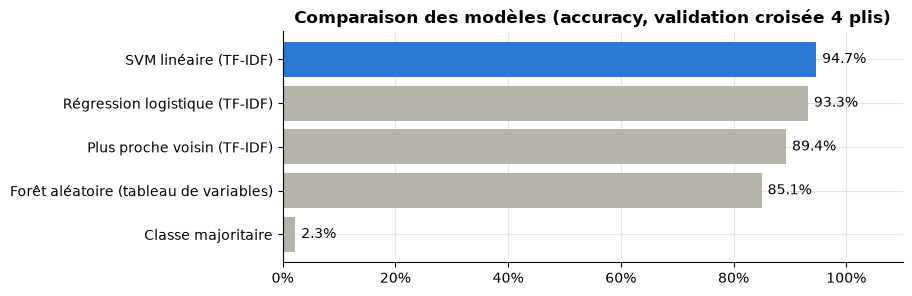

In [14]:
acc = pd.Series({nom: r[0] for nom, r in resultats.items()}).sort_values()
plt.figure(figsize=(8, 3))
plt.barh(acc.index, acc.values, color=[BLEU if v == acc.max() else GRIS for v in acc])
for i, v in enumerate(acc.values):
    plt.text(v + 0.01, i, f"{v:.1%}", va="center")
plt.xlim(0, 1.1)
plt.gca().xaxis.set_major_formatter(pourcent)
plt.title("Comparaison des modèles (accuracy, validation croisée 4 plis)")
plt.show()

**Ce qu'on retient.**
- Tous les modèles battent très largement le repère de 2,3 %.
- La **forêt aléatoire** sur un tableau de variables résumées atteint déjà 85 %. Mais résumer une session en une cinquantaine de nombres fait perdre de l'information : on ne sait plus quels écrans ni quelles chaînes ont été utilisés.
- Le **plus proche voisin** (89 %) confirme l'exploration : chercher la session la plus ressemblante marche bien. Mais il se fie à une seule session, donc il est sensible au bruit.
- Les **modèles linéaires sur TF-IDF** sont les meilleurs, et le **SVM linéaire** gagne (environ 95 %). Pourquoi ?
    - On a beaucoup de variables (des dizaines de milliers de mots et bigrammes) et peu d'exemples par classe. Dans ce cas, les classes sont presque toujours séparables par une frontière linéaire, et un modèle plus complexe surapprendrait.
    - Les vecteurs TF-IDF sont **creux** (presque tous les mots valent 0 dans une session donnée) : les modèles linéaires les traitent très vite.
    - Le SVM cherche la frontière qui laisse la plus grande **marge** entre les classes, ce qui limite le surapprentissage quand il y a peu d'exemples.
- Pour 247 classes, le SVM entraîne en fait 247 classifieurs « cet utilisateur contre tous les autres », et choisit celui qui donne le score le plus élevé.

## 6. Qu'est-ce qui améliore le score ?

### 6.1 Ajouter les informations une par une

On garde le meilleur modèle (le SVM linéaire) et on ajoute les informations une à une, pour mesurer l'apport de chacune. C'est une **étude d'ablation**.

In [15]:
etapes = {
    "types d'action seuls": dict(details=False, avec_nav=False, bigrammes=False),
    "+ bigrammes (ordre)": dict(details=False, avec_nav=False, bigrammes=True),
    "+ écrans, configs, chaînes": dict(details=True, avec_nav=False, bigrammes=True),
    "+ navigateur": dict(details=True, avec_nav=True, bigrammes=True),
}
ablation = {}
for nom, options in etapes.items():
    X = [session_en_texte(s, n, options["details"], options["avec_nav"]) for s, n in zip(sessions, nav)]
    modele = make_pipeline(tfidf(options["bigrammes"]), LinearSVC(C=0.5))
    ablation[nom] = evaluer(modele, X)[0]
    print(f"{nom:30s} {ablation[nom]:.1%}")

types d'action seuls           59.4%


+ bigrammes (ordre)            84.7%


+ écrans, configs, chaînes     94.1%


+ navigateur                   94.7%


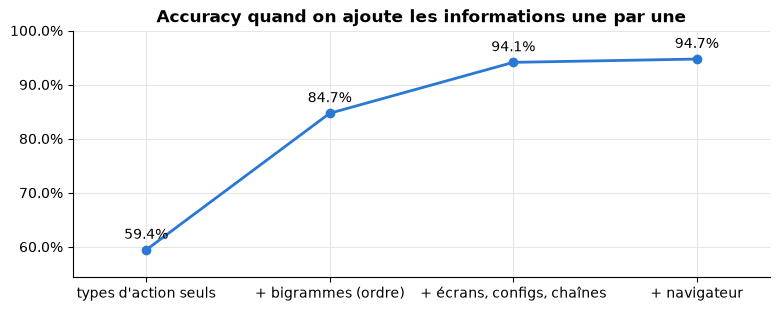

In [16]:
valeurs = list(ablation.values())
plt.figure(figsize=(9, 3.2))
plt.plot(list(ablation), valeurs, marker="o", color=BLEU, lw=2)
for i, v in enumerate(valeurs):
    plt.annotate(f"{v:.1%}", (i, v), xytext=(0, 8), textcoords="offset points", ha="center")
plt.ylim(min(valeurs) - 0.05, 1)
plt.xlim(-0.4, len(valeurs) - 0.6)
plt.gca().yaxis.set_major_formatter(pourcent)
plt.title("Accuracy quand on ajoute les informations une par une")
plt.show()

**Ce qu'on retient.**
- Avec les **types d'action seuls**, on n'atteint que 59 % : 35 types d'action ne suffisent pas à distinguer 247 personnes (c'est ce que montrait le chevauchement en 3.5).
- Les **bigrammes** font le plus gros saut (+25 points) : l'**ordre** dans lequel une personne enchaîne ses actions est très personnel (par exemple « raccourci puis bouton » contre « clic puis dialogue »).
- Les **écrans, configurations et chaînes** ajoutent encore 9 points : ils disent **sur quoi** la personne travaille (son métier : comptabilité, production, ventes...).
- Le **navigateur** n'ajoute plus que 0,6 point : une fois qu'on connaît les écrans et les habitudes, on sait déjà presque toujours qui c'est.
- Chaque information ajoutée améliore le score : on garde tout.

### 6.2 Régler le paramètre de régularisation C

C règle le compromis entre « coller » aux données d'entraînement (C grand, risque de **surapprentissage**) et garder un modèle plus simple (C petit, risque de **sous-apprentissage**). On essaie plusieurs valeurs.

In [17]:
scores_C = {}
for C in [0.1, 0.3, 1, 3, 10, 30]:
    scores_C[C] = evaluer(make_pipeline(tfidf(), LinearSVC(C=C)), textes)[0]
    print(f"C = {C:<4} accuracy = {scores_C[C]:.1%}")

meilleur_C = max(scores_C, key=scores_C.get)
print("Meilleur C :", meilleur_C)

C = 0.1  accuracy = 88.6%


C = 0.3  accuracy = 92.8%


C = 1    accuracy = 95.5%


C = 3    accuracy = 96.2%


C = 10   accuracy = 96.2%


C = 30   accuracy = 96.1%
Meilleur C : 10


**Ce qu'on retient.**
- Avec C trop petit (0,1), le modèle est trop **contraint** : il sous-apprend (89 %).
- Le score monte jusqu'à environ 96,2 % à partir de C = 3, puis reste **stable** jusqu'à 30. Entre 3, 10 et 30, les écarts (0,1 point au plus) sont bien plus petits que la variation d'un pli à l'autre : ces valeurs sont équivalentes. Le code garde celle qui a le meilleur score, C = 10.
- **Attention à la grille :** si le meilleur C avait été la plus grande valeur testée, il aurait fallu essayer plus grand. C'est pour cela qu'on teste aussi 10 et 30.
- Le réglage apporte 1,5 point par rapport à la valeur par défaut utilisée en partie 5 (C = 0,5). La régression logistique aurait aussi gagné à être réglée, mais le SVM reste notre choix : il est plus rapide et déjà très bon.

## 7. Comprendre les erreurs et le modèle

### 7.1 Quelles sessions sont mal classées ?

`cross_val_predict` donne, pour chaque session, la prédiction faite quand elle était dans le pli de test.

Accuracy : 96.2% (125 erreurs sur 3279)


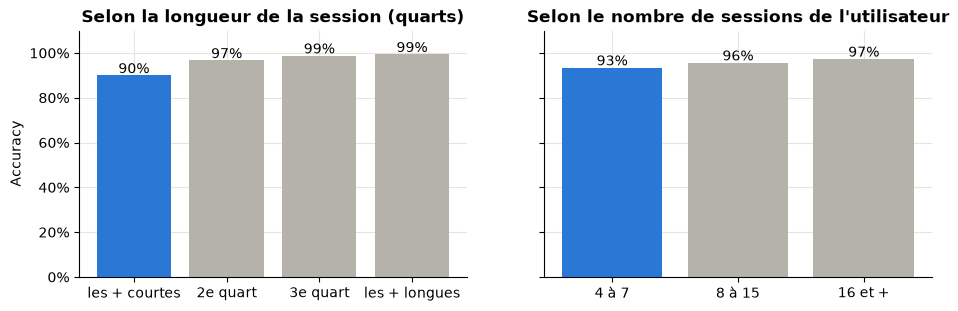

In [18]:
modele_final = make_pipeline(tfidf(), LinearSVC(C=meilleur_C))
predictions = cross_val_predict(modele_final, textes, y, cv=cv, n_jobs=4)
stats["correct"] = predictions == y
print(f"Accuracy : {stats.correct.mean():.1%} ({(~stats.correct).sum()} erreurs sur {len(y)})")

stats["longueur"] = pd.qcut(stats.nb_actions, 4, labels=["les + courtes", "2e quart", "3e quart", "les + longues"])
stats["nb_sessions_util"] = pd.cut(stats.utilisateur.map(sessions_par_util), [0, 7, 15, 100], labels=["4 à 7", "8 à 15", "16 et +"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, colonne, titre in [(ax1, "longueur", "Selon la longueur de la session (quarts)"),
                           (ax2, "nb_sessions_util", "Selon le nombre de sessions de l'utilisateur")]:
    taux = stats.groupby(colonne, observed=True).correct.mean()
    ax.bar(taux.index.astype(str), taux.values, color=[BLEU if v == taux.min() else GRIS for v in taux])
    for i, v in enumerate(taux.values):
        ax.text(i, v + 0.01, f"{v:.0%}", ha="center")
    ax.set(title=titre, ylim=(0, 1.1))
    ax.yaxis.set_major_formatter(pourcent)
ax1.set_ylabel("Accuracy")
plt.show()

**Ce qu'on retient.**
- Le modèle fait environ 125 erreurs sur 3 279 sessions (96 %). *Remarque d'honnêteté :* C a été choisi avec ces mêmes plis, donc ce chiffre est très légèrement optimiste. Le score Kaggle donnera une mesure indépendante.
- Les **sessions courtes** sont les plus difficiles (90 % pour le quart le plus court, 99 % pour les plus longues) : avec peu d'actions, il y a peu d'indices sur la personne.
- Les **utilisateurs rares** (4 à 7 sessions) sont un peu moins bien reconnus (93 %) : le modèle a moins d'exemples pour apprendre leur profil.
- Ces deux faiblesses sont attendues et ne viennent pas d'un défaut du code : elles viennent de la quantité d'information disponible.

### 7.2 Quels mots le modèle utilise-t-il ?

Un modèle linéaire apprend **un poids par mot et par utilisateur**. Les mots de plus fort poids pour un utilisateur forment sa « signature ».

In [19]:
modele_final.fit(textes, y)
vocabulaire = modele_final[0].get_feature_names_out()
poids = modele_final[-1].coef_

signatures = {}
for util in sessions_par_util.index[:4]:
    ligne = poids[list(modele_final[-1].classes_).index(util)]
    signatures[util] = vocabulaire[np.argsort(ligne)[::-1][:8]]
pd.DataFrame(signatures)

,skm,slq,cjr,flj
0,CONF_ADM_055,Affichage_d_une_dialogue ECRAN_HomeViewController,ECRAN_FormulaireForm,CONF_LERCNAT
1,Raccourci MODIF,NAV_Google_Chrome Exécution_d_un_bouton,Clic_sur_une_grille_d_historique_de_recherche ...,Sélection_d_un_onglet CONF_LERCNAT
2,Raccourci ECRAN_SaisiEcritForm,ECRAN_FicheFournisseurForm Sélection_d_un_onglet,ECRAN_EXPO,ECRAN_AvoirForm Raccourci
3,ECRAN_InputFormNestedWindow CONF_ADM_055,Saisie_dans_un_champ ECRAN_SaisiEcritForm,CONF_SuiviProdLog,ECRAN_InputFormNestedWindow CONF_LERCNAT
4,Clic_long MODIF,ECRAN_InterventionController Sélection_d_un_on...,ECRAN_BlankController CONF_SuiviProdLog,CONF_EV_BK
5,Sélection_d_un_onglet CONF_ADM_055,Exécution_d_un_bouton ECRAN_PdfViewerForm,ECRAN_CompteRenduForm Fermeture_de_session,CONF_LERCNAT Exécution_d_un_bouton
6,Raccourci,Lancement_d_une_stat Exécution_d_un_bouton,ECRAN_PlanifRepetitiveForm,CONF_LERCNAT Saisie_dans_un_champ
7,MODIF Clic_long,Lancement_d_une_stat Saisie_dans_un_champ,ECRAN_CompteRenduForm,CONF_LERCNAT MODIF


**Ce qu'on retient.**
- Chaque colonne donne les 8 mots (ou bigrammes) les plus caractéristiques d'un utilisateur.
- On y trouve surtout des **configurations d'écran** (`CONF_...`) et des **écrans** (`ECRAN_...`) précis, souvent combinés à une action : par exemple une configuration propre à un service, ou un formulaire de facturation.
- Le modèle reconnaît donc une personne avant tout à **ce sur quoi elle travaille**, puis à **sa manière d'enchaîner les actions**. C'est logique : dans une entreprise, chaque employé a son poste et ses écrans habituels.

## 8. Créer le fichier de soumission

Le modèle final est entraîné sur **toutes** les sessions du train (cellule précédente), puis appliqué au test.

In [20]:
predictions_test = modele_final.predict(textes_test)
soumission = pd.DataFrame({"RowId": range(1, len(predictions_test) + 1), "prediction": predictions_test})
soumission.to_csv("submission.csv", index=False)
print(len(soumission), "prédictions enregistrées dans submission.csv")
soumission.head()

324 prédictions enregistrées dans submission.csv


,RowId,prediction
0,1,hzx
1,2,prb
2,3,jmq
3,4,psg
4,5,cvw


## Conclusion

| Étape | Choix | Pourquoi |
|---|---|---|
| Lecture | ligne par ligne, une liste par session | les sessions ont des longueurs très différentes |
| Valeurs extrêmes | gardées | sessions réelles, présentes aussi dans le test ; TF-IDF les neutralise |
| Représentation | session = texte de « mots » (action, écran, config, chaîne, navigateur) + bigrammes, pondéré par TF-IDF | garde l'information détaillée et l'ordre des actions |
| Évaluation | validation croisée stratifiée à 4 plis, TF-IDF dans le pipeline | utilisateur le plus rare = 4 sessions ; pas de fuite de données |
| Modèle | SVM linéaire, C = 10 | meilleur score (96 %), rapide, adapté à beaucoup de variables et peu d'exemples |

**Ce qu'on a appris :** les utilisateurs se reconnaissent surtout par les écrans et configurations qu'ils utilisent, et par l'ordre de leurs actions. Les sessions courtes et les utilisateurs avec peu de sessions restent les cas difficiles.

**Pistes d'amélioration :** donner plus de poids aux utilisateurs rares (`class_weight="balanced"`), ajouter des trigrammes, ou combiner le SVM et la régression logistique.